In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import ast

df = pd.read_csv("data/interim/foundersFeatures_FINAL.csv", index_col=0)

df['active_since'] = pd.to_datetime(df['active since'], unit='s')
df["num_subs_safe"] = df["subreddits"].apply(lambda x: len(ast.literal_eval(x)) + 1)
df["num_contrib_safe"] = df["num contributions"].apply(lambda x: x+1)

Log-Log features plots

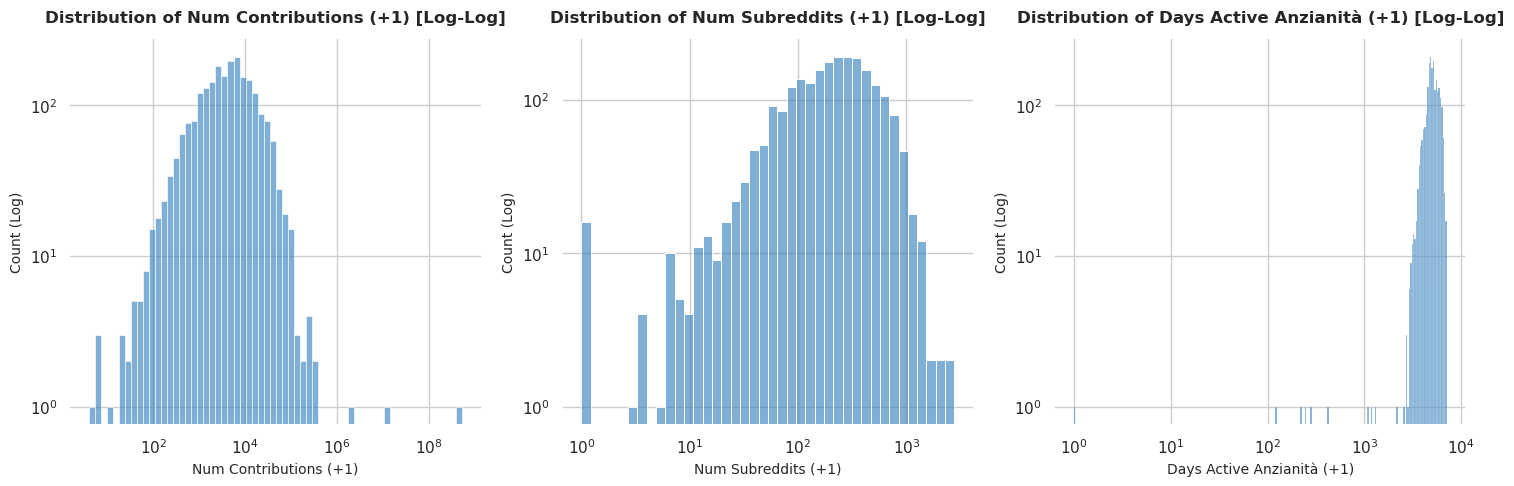

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. TRASFORMAZIONE DEL TIMESTAMP UNIX IN GIORNI DI ATTIVITÀ
# Troviamo il timestamp massimo nel dataset (il giorno più recente registrato)
max_unix_timestamp = df['active since'].max()

# Calcoliamo i giorni di vita del profilo e aggiungiamo +1 per la scala logaritmica
df['days_active_safe'] = ((max_unix_timestamp - df['active since']) / (60 * 60 * 24)) + 1

# 2. CONFIGURAZIONE DELLO STILE E DEL PANNELLO (Ora a 3 colonne)
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(18, 5)) # Allargato a 18 per far stare 3 grafici puliti

# Aggiorniamo le liste con la terza feature temporale
features = ['num_contrib_safe', 'num_subs_safe', 'days_active_safe']
titles = ['Num Contributions (+1)', 'Num Subreddits (+1)', 'Days Active Anzianità (+1)']

# 3. CICLO DI GENERAZIONE DEI GRAFICI LOG-LOG
for ax, feature, title in zip(axes, features, titles):
    sns.histplot(
        data=df,
        x=feature,
        log_scale=True,      # 1. Fa i bin logaritmici sui dati (Asse X)
        element='bars',
        color='#2b7bba',     # Blu elegante coordinato
        alpha=0.6,
        ax=ax
    )
    
    # 2. Trasforma l'asse Y (i conteggi degli utenti) in scala logaritmica
    ax.set_yscale('log')
    
    # Formattazione estetica del singolo quadrante
    ax.set_title(f"Distribution of {title} [Log-Log]", fontsize=12, fontweight='bold', pad=12)
    ax.set_xlabel(title, fontsize=10)
    ax.set_ylabel("Count (Log)", fontsize=10)
    sns.despine(ax=ax, left=True, bottom=True)

# Mostra il pannello finale senza warning di sovrapposizione
# Modificare semplicemente la data in cui prendo i contributi (prendere quelli fino a before founding event)'
plt.show()

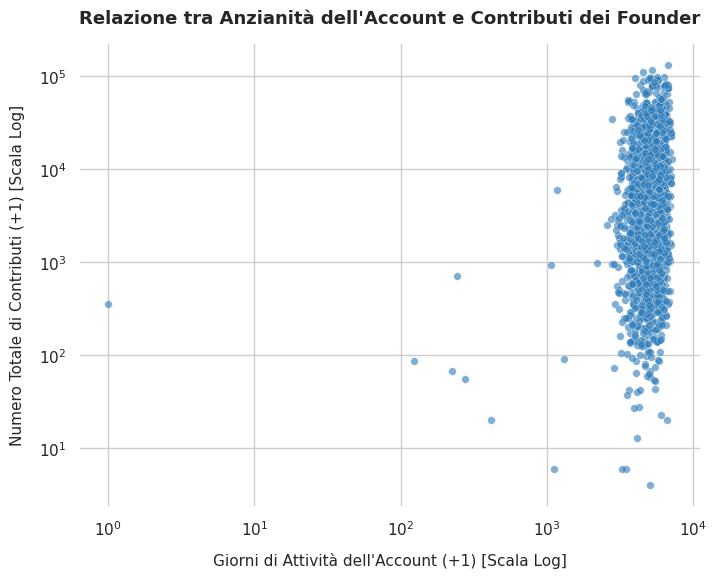

In [18]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. CALCOLO DELLE FEATURE REALI DALLE TUE COLONNE
# Calcoliamo i giorni di attività partendo dal timestamp Unix massimo
max_unix = df['active since'].max()
df['days_active'] = (max_unix - df['active since']) / 86400

# Applichiamo la trasformazione $X + 1$ di sicurezza per evitare errori con il logaritmo di zero
df['days_active_safe'] = df['days_active'] + 1
df['num_contrib_safe'] = df['num contributions'] + 1

# 2. CONFIGURAZIONE DELLO STILE SEABORN
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(8, 6))

# 3. CREAZIONE DEL PLOT A DISPERSIONE
sns.scatterplot(
    data=df,
    x='days_active_safe',
    y='num_contrib_safe',
    alpha=0.6,           # Semitrasparenza per gestire la sovrapposizione dei punti
    color='#2b7bba',     # Un blu moderno e professionale
    edgecolor='w',       # Bordo bianco intorno ai pallini per separarli visivamente
    linewidth=0.3,
    s=30,                # Dimensione bilanciata dei punti
    ax=ax
)

# 4. APPLICAZIONE DELLA SCALA LOG-LOG
ax.set_xscale('log')
ax.set_yscale('log')

# 5. ETICHETTE E PULIZIA ESTETICA
# Rimuoviamo i bordi neri inutili per pulire il grafico (look da paper)
sns.despine(left=True, bottom=True)

ax.set_xlabel("Giorni di Attività dell'Account (+1) [Scala Log]", fontsize=11, labelpad=10)
ax.set_ylabel("Numero Totale di Contributi (+1) [Scala Log]", fontsize=11, labelpad=10)
ax.set_title("Relazione tra Anzianità dell'Account e Contributi dei Founder", fontsize=13, pad=15, fontweight='bold')

# 6. SALVATAGGIO AD ALTA RISOLUZIONE (Senza usare plt.show() per evitare warning di layout)
plt.savefig("days_active_vs_contributions.png", dpi=300, bbox_inches='tight')